## Pegasus Evaluation: SLO-based Composition Planning

Section C.2. An application type (vision, audio, lidar) has five service compositions, the application instances V1
to V5, A1 to A5 and L1 to L5: the chains `b1u-<application>-<i>` of the second campaign (V1 is `b1u-vision-1`). A
client of an application states its requirements as SLOs on three dimensions, and a numerical solver chooses the
composition and its configuration that meets them, as in the RASK paper (SummerSOC, `agent/components/Optimizer_v2.py`).
The chosen configurations are then deployed on the testbed; the deployment table at the end lists them.
Implementation: `slo_planning.py` (next to this notebook, outside `pegasus/`, so that the cached experiments of B.1 to
C.1 are not recomputed). C.1: `2e_finetuning.ipynb`.

**Configuration of a composition** with $K$ services:
- $q$, the data quality that every service of the composition processes (knob `data_quality`, shared by all services):
  the image width in pixels for vision, the clip length in seconds for audio, the radius of the point cloud in meters
  for lidar; a larger $q$ counts as a higher quality;
- $w_k \in \{1, \dots, 4\}$, the number of workers of service $k$ (knob `parallelism`); at deployment, service $k$ gets
  $w_k + 0.5$ cores (`sp.CORE_HEADROOM`), as in the campaign runs;
- $m_k \in \{1, 2\}$, the model size of every detector that has one (knob `model_size`, vision only).

**SLO dimensions**, one number per configuration:
- *cost*: the total number of workers, $\sum_k w_k$;
- *latency*: the Pegasus Node bound (s) on the p95 of the end-to-end latency at the arrival rate $\lambda$ (items/s,
  Poisson arrivals) of the scenario, with the load-aware models of B.1 (`load_aware_b4.py`). Every service is bounded
  on its own with the violation probability $\varepsilon = \alpha / K$ ($\alpha = 0.05$ for the p95), and the
  end-to-end bound is the sum of the $K$ node bounds plus the handover time between the services. A configuration in
  which a service is overloaded (its queue grows without limit, so Pegasus Node has no finite bound) is never feasible;
- *quality*: $q$; for vision a scenario may also require a smallest model size $\min_k m_k$ among the detectors of the
  composition (a composition without a detector has model size 0).

A **scenario** (S-V-1 to S-V-5, S-A-1 to S-A-5, S-L-1 to S-L-5) has its own arrival rate $\lambda$ and constrains one
or two of these dimensions (at most so many workers, at most this p95, at least this quality). Every dimension that it
does not constrain is *free* and is optimized: the objective is the weighted sum of the free dimensions, each divided
by its typical value in the scenario, with a weight per free dimension that the scenario sets. The constrained dimensions enter with the weight
`TIE_WEIGHT`, which only breaks ties. A scenario also names the one or two capabilities it needs (its functional
requirement, without an order of the services); only compositions that contain a service for each of them are
candidates.

**Training data.** Every service of a composition is trained as in B.1 on its benchmark and its runs in the other
chains, without any run of the composition itself: a composition is planned as if it had never run.

- **C.2a. Scenarios:** five sets of SLOs per application, with their arrival rates and weights.
- **C.2b. SLSQP on the continuous relaxation:** the solver of the RASK paper and of the deployed plans, restarted from random points per composition.
- **C.2c. Exhaustive search (reference):** every grid configuration of every composition.
- **C.2d. Results:** the plans, the agreement of the two solvers, the trade-off per scenario, the deployment table.

The setup cell below fits (or reads from `statics/slo_planning/`) the models of every composition and lists the
arrival rates that every composition had in its training runs; C.2a computes the node bounds at the rate of every
scenario. Results are compared in C.2d.

In [1]:
import time

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import slo_planning as sp
from slo_planning import Scenario

WORKER_BUDGET = 8                  # workers; the budget of a trade-off panel in C.2d for a scenario without a worker limit

# The load-aware GPs receive log10 of the arrival rate, so the rate of a scenario should lie within the rates that all
# services of its candidate compositions had in their training runs: the columns rate_low and rate_high (items/s).
# rate_low > rate_high: the services of the composition never shared a rate, so every rate extrapolates one of them.
ranges = {experiment: sp.rate_range(experiment) for experiments in sp.APPLICATIONS.values() for experiment in experiments}
display(pd.DataFrame([dict(application=app, composition=sp.label(e), experiment=e, services=" → ".join(sp.fit_composition(e)["path"]),
                           K=len(sp.fit_composition(e)["path"]), rate_low=ranges[e][0], rate_high=ranges[e][1])
                      for app, experiments in sp.APPLICATIONS.items() for e in experiments])
        .set_index(["application", "composition"]).style.format(dict(rate_low="{:.1f}", rate_high="{:.1f}")))

### C.2a. Scenarios

Five scenarios per application, named S-V-1 to S-V-5, S-A-1 to S-A-5 and S-L-1 to S-L-5. Every scenario has an arrival
rate within the training rates of its candidate compositions where they have one in common (setup cell; the second
table below lists the services whose training runs never had the rate), one or two constraints, a weight for every
free dimension, and a note on the client that would pose it. Its *functional requirement* names one or two
capabilities (e.g. voice activity, face detection) that several compositions provide, so that the solver chooses among
several candidates. A composition meets the requirement if it contains a service for every required capability
(`sp.CAPABILITIES` maps capabilities to services); any other composition is excluded before the solver runs.

**Weights act on relative changes.** In the objective, every dimension is divided by its *typical value* in the
scenario: the median of that dimension over all grid configurations of the candidate compositions that meet the
scenario's constraints (`sp.typical_scales`; columns `typical_*` of the second table below). A weight therefore prices a
change relative to what is typical for this client. Example with typical values of 500 px and 500 ms and weights
quality 1 and latency 0.5: 50 px more (10 % of 500 px, times weight 1) are worth 100 ms more latency (20 % of 500 ms,
times weight 0.5). A small weight for latency marks a client without a deadline, for whom latency still counts.

In [2]:
# Scenario(name, arrival rate in items/s, weights of the free dimensions, constraints, requires=capabilities, note=client)
SCENARIOS = {
    "vision": [
        Scenario("S-V-1 edge box", 15.0, dict(latency=0.5, quality=1.0), max_workers=6, requires=("object detection",),
                 note="a 15 fps camera with an edge box that has 6 cores for the pipeline; detects objects"),
        Scenario("S-V-2 interactive AR", 30.0, dict(cost=1.0, quality=0.5), max_latency=0.100, requires=("face detection",),
                 note="an augmented-reality face filter at 30 fps that must follow the scene within three frames"),
        Scenario("S-V-3 forensic detail", 12.0, dict(cost=1.0, latency=0.1), min_quality=512, min_model=2, requires=("object detection",),
                 note="incident review of a 12 fps camera: objects at 512 px or more with the larger model; latency matters little"),
        Scenario("S-V-4 retail analytics", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("QR codes",),
                 note="a store camera at 15 fps that reads product codes within 250 ms"),
        Scenario("S-V-5 traffic monitoring", 25.0, dict(latency=1.0, quality=1.0), max_workers=10, requires=("motion detection",),
                 note="a roadside unit with 10 cores that detects moving vehicles in a 25 fps stream"),
    ],
    "audio": [
        Scenario("S-A-1 shared gateway", 6.0, dict(latency=0.5, quality=1.0), max_workers=4, requires=("noise suppression",),
                 note="noise suppression of 6 clips per second on a gateway that grants the pipeline 4 cores"),
        Scenario("S-A-2 voice assistant", 6.0, dict(cost=1.0, quality=0.2), max_latency=0.050, requires=("voice activity",),
                 note="a voice assistant that detects speech in 6 clips per second and must respond without a noticeable pause"),
        Scenario("S-A-3 music archive", 3.0, dict(cost=1.0, latency=0.1), min_quality=10, requires=("audio encoding",),
                 note="recordings encoded for an archive in clips of 10 s or more; latency matters little"),
        Scenario("S-A-4 call analytics", 6.0, dict(latency=1.0), max_workers=6, min_quality=6, requires=("voice activity",),
                 note="speech detection in recorded calls, 6 clips per second in clips of 6 s or more, on 6 cores; results as fast as possible"),
        Scenario("S-A-5 conferencing", 6.0, dict(cost=1.0, quality=0.5), max_latency=0.150, requires=("noise suppression",),
                 note="a conference call with noise suppression within the 150 ms mouth-to-ear budget of ITU-T G.114"),
    ],
    "lidar": [
        Scenario("S-L-1 delivery robot", 12.0, dict(latency=1.0, quality=1.0), max_workers=6, requires=("clustering",),
                 note="obstacle clusters from a 12 Hz lidar on the embedded computer of a delivery robot with 6 cores"),
        Scenario("S-L-2 collision avoidance", 12.0, dict(cost=1.0, quality=1.0), max_latency=0.080, requires=("ground removal",),
                 note="obstacles above the ground must be known before the next scan of a 12 Hz lidar (80 ms)"),
        Scenario("S-L-3 HD mapping", 12.0, dict(cost=1.0, latency=0.1), min_quality=30, requires=("registration",),
                 note="offline map building from registered scans with a radius of 30 m or more; latency matters little"),
        Scenario("S-L-4 fleet perception", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("normal estimation",),
                 note="surface normals for a fleet of slow vehicles, results within 250 ms"),
        Scenario("S-L-5 robotaxi", 20.0, dict(quality=1.0), max_workers=10, max_latency=0.200, requires=("point cloud encoding",),
                 note="a 10-core perception box that streams the encoded cloud of a 20 Hz lidar to remote operators within 200 ms"),
    ],
}
display(pd.DataFrame([dict(application=app, scenario=s.name, rate=s.rate, constraints=s.constraints(), objective=s.goal(),
                           requires=", ".join(s.requires), client=s.note) for app, scenarios in SCENARIOS.items() for s in scenarios])
        .set_index(["application", "scenario"]))

rate                 constraints  \
application scenario                                                      
vision      S-V-1 edge box             15.0                 ≤ 6 workers   
            S-V-2 interactive AR       30.0                p95 ≤ 100 ms   
            S-V-3 forensic detail      12.0    quality ≥ 512, model ≥ 2   
            S-V-4 retail analytics     15.0                p95 ≤ 250 ms   
            S-V-5 traffic monitoring   25.0                ≤ 10 workers   
audio       S-A-1 shared gateway        6.0                 ≤ 4 workers   
            S-A-2 voice assistant       6.0                 p95 ≤ 50 ms   
            S-A-3 music archive         3.0                quality ≥ 10   
            S-A-4 call analytics        6.0    ≤ 6 workers, quality ≥ 6   
            S-A-5 conferencing          6.0                p95 ≤ 150 ms   
lidar       S-L-1 delivery robot       12.0                 ≤ 6 workers   
            S-L-2 collision avoidance  12.0                 p95 ≤ 80 ms   
            S-L-3 HD mapping           12.0                quality ≥ 30   
            S-L-4 fleet perception     15.0                p95 ≤ 250 ms   
            S-L-5 robotaxi             20.0  ≤ 10 workers, p95 ≤ 200 ms   

                                                                 objective  \
application scenario                                                         
vision      S-V-1 edge box             min latency (0.5) + max quality (1)   
            S-V-2 interactive AR          min cost (1) + max quality (0.5)   
            S-V-3 forensic detail         min cost (1) + min latency (0.1)   
            S-V-4 retail analytics        min cost (1) + max quality (0.5)   
            S-V-5 traffic monitoring     min latency (1) + max quality (1)   
audio       S-A-1 shared gateway       min latency (0.5) + max quality (1)   
            S-A-2 voice assistant         min cost (1) + max quality (0.2)   
            S-A-3 music archive           min cost (1) + min latency (0.1)   
            S-A-4 call analytics                           min latency (1)   
            S-A-5 conferencing            min cost (1) + max quality (0.5)   
lidar       S-L-1 delivery robot         min latency (1) + max quality (1)   
            S-L-2 collision avoidance       min cost (1) + max quality (1)   
            S-L-3 HD mapping              min cost (1) + min latency (0.1)   
            S-L-4 fleet perception        min cost (1) + max quality (0.5)   
            S-L-5 robotaxi                                 max quality (1)   

                                                   requires  \
application scenario                                          
vision      S-V-1 edge box                 object detection   
            S-V-2 interactive AR             face detection   
            S-V-3 forensic detail          object detection   
            S-V-4 retail analytics                 QR codes   
            S-V-5 traffic monitoring       motion detection   
audio       S-A-1 shared gateway          noise suppression   
            S-A-2 voice assistant            voice activity   
            S-A-3 music archive              audio encoding   
            S-A-4 call analytics             voice activity   
            S-A-5 conferencing            noise suppression   
lidar       S-L-1 delivery robot                 clustering   
            S-L-2 collision avoidance        ground removal   
            S-L-3 HD mapping                   registration   
            S-L-4 fleet perception        normal estimation   
            S-L-5 robotaxi             point cloud encoding   

                                                                                  client  
application scenario                                                                      
vision      S-V-1 edge box             a 15 fps camera with an edge box that has 6 co...  
            S-V-2 interactive AR       an augmented-reality face filter at 30 fps tha...  


In [3]:
# compositions[scenario name]: the five compositions of the application with the node bounds of every service on its
# knob grid at the arrival rate of the scenario (scenarios with the same application and rate share the tables)
tables = {}
compositions = {s.name: [tables.setdefault((e, s.rate), sp.composition(e, s.rate)) for e in sp.APPLICATIONS[app]]
                for app, scenarios in SCENARIOS.items() for s in scenarios}
# scales[scenario name]: the typical cost, latency and quality of the scenario, which normalize the objective
scales = {s.name: sp.typical_scales(compositions[s.name], s) for scenarios in SCENARIOS.values() for s in scenarios}
# per scenario: the candidate compositions (those with every required capability), the size of their knob grids, the
# services whose training runs never had the scenario's rate (their GPs extrapolate the load input), the typical values
candidates = {s.name: [c for c in compositions[s.name] if sp.provides(c, s.requires)] for scenarios in SCENARIOS.values() for s in scenarios}
display(pd.DataFrame([dict(application=app, scenario=s.name, rate=s.rate, candidates=", ".join(c.label for c in candidates[s.name]),
                           grid_configurations=", ".join(f"{len(sp.all_grid_indices(c)):,}" for c in candidates[s.name]),
                           rate_outside_training="; ".join(f"{c.label}: {', '.join(c.extrapolated)}" for c in candidates[s.name] if c.extrapolated) or "–",
                           typical_workers=scales[s.name].cost, typical_p95_ms=1e3 * scales[s.name].latency, typical_quality=scales[s.name].quality)
                      for app, scenarios in SCENARIOS.items() for s in scenarios]).set_index(["application", "scenario"])
        .style.format(dict(typical_workers="{:g}", typical_p95_ms="{:.0f}", typical_quality="{:g}")))

### C.2b. SLSQP on the Continuous Relaxation

The solver of the plans, as in the RASK paper: `scipy.optimize.minimize` with SLSQP on the knobs normalized to
$[0, 1]$, started from `RESTARTS` random points per composition. The objective is the weighted sum of the scenario's
free dimensions, each divided by its typical value (C.2a), plus `TIE_WEIGHT` times each constrained dimension; the
constraints of the scenario are inequality constraints of SLSQP, also divided by the typical values.

SLSQP needs continuous knobs, but $q$, $w_k$ and $m_k$ take values on a grid, and Pegasus Node needs a whole number of
workers. The latency of the relaxation therefore interpolates every node bound linearly between the grid points; an
overloaded service (no finite bound) gets `OVERLOAD_LATENCY` instead, so that SLSQP moves away from it. Every SLSQP
solution is rounded to the nearest grid point and repaired: among the grid configurations within one grid step of it
in every knob, the best that meets every constraint with the exact bound is kept. The plan of a scenario is the
composition whose best configuration has the smallest objective; a scenario without any such configuration has no
plan.

In [4]:
rng = np.random.default_rng(sp.seed)   # the starting points of SLSQP
plans_slsqp, seconds = {}, dict(slsqp={}, exhaustive={})
for app, scenarios in SCENARIOS.items():
    for scenario in scenarios:
        started = time.perf_counter()
        plans_slsqp[(app, scenario.name)] = sp.plan(compositions[scenario.name], scenario, scales[scenario.name], "slsqp", rng)
        seconds["slsqp"][(app, scenario.name)] = time.perf_counter() - started

### C.2c. Exhaustive Search (Reference)

Every grid configuration of every candidate composition is evaluated with the exact node bounds, and the best that
meets the constraints is kept. The number of grid configurations of a composition is the number of qualities times
$4^K$ worker settings times $2$ per detector (column `grid_configurations` in C.2a). Enumerating them is possible here
because the end-to-end bound of Pegasus Node is a sum of node bounds that each depend only on the knobs of their own
service: the bounds of all configurations are sums of table entries. The exhaustive search tells whether SLSQP found
the optimum of the grid; it does not replace SLSQP for compositions whose grid is too large to enumerate.

In [5]:
plans_exhaustive = {}
for app, scenarios in SCENARIOS.items():
    for scenario in scenarios:
        started = time.perf_counter()
        plans_exhaustive[(app, scenario.name)] = sp.plan(compositions[scenario.name], scenario, scales[scenario.name], "exhaustive")
        seconds["exhaustive"][(app, scenario.name)] = time.perf_counter() - started

### C.2d. Results

**Plans.** One table per application: one row per scenario, one column per composition. A cell holds the best
configuration of that composition for that scenario found by SLSQP, as total workers, data quality and Pegasus bound on
the p95 end-to-end latency (ms); "no capability" where the composition lacks a required capability, "–" where SLSQP
found no configuration that meets the SLOs. The column `plan` names the chosen composition.

In [6]:
def cell(row) -> str:
    if not row["functional"]:
        return "no capability"
    return f"{int(row['workers'])} w, q {row['data_quality']:g}, {row['latency_ms']:.0f} ms" if row["feasible"] else "–"

for app, scenarios in SCENARIOS.items():
    display(Markdown(f"**{app}**, q in {sp.QUALITY_UNITS[app]}"))
    rows = []
    for scenario in scenarios:
        table = plans_slsqp[(app, scenario.name)]
        rows.append({"scenario": scenario.name, "rate": scenario.rate, "SLOs": scenario.constraints(), "requires": ", ".join(scenario.requires),
                     "objective": scenario.goal(), **{sp.label(row["composition"]): cell(row) for _, row in table.sort_values("composition").iterrows()},
                     "plan": sp.label(table.iloc[0]["composition"]) if table.iloc[0]["feasible"] else "none"})
    display(pd.DataFrame(rows).set_index("scenario"))

**vision**, q in image width (px)

,rate,SLOs,requires,objective,V1,V2,V3,V4,V5,plan
scenario,,,,,,,,,,
S-V-1 edge box,15.0,≤ 6 workers,object detection,min latency (0.5) + max quality (1),"6 w, q 544, 267 ms",no capability,"6 w, q 480, 230 ms",no capability,"6 w, q 320, 184 ms",V1
S-V-2 interactive AR,30.0,p95 ≤ 100 ms,face detection,min cost (1) + max quality (0.5),no capability,"4 w, q 352, 98 ms","5 w, q 256, 84 ms",no capability,"6 w, q 224, 96 ms",V2
S-V-3 forensic detail,12.0,"quality ≥ 512, model ≥ 2",object detection,min cost (1) + min latency (0.1),"5 w, q 512, 1725 ms",no capability,"7 w, q 512, 2102 ms",no capability,"9 w, q 512, 2471 ms",V1
S-V-4 retail analytics,15.0,p95 ≤ 250 ms,QR codes,min cost (1) + max quality (0.5),no capability,no capability,no capability,"6 w, q 544, 231 ms","7 w, q 448, 238 ms",V4
S-V-5 traffic monitoring,25.0,≤ 10 workers,motion detection,min latency (1) + max quality (1),no capability,no capability,no capability,"10 w, q 384, 116 ms","10 w, q 384, 145 ms",V4


**audio**, q in clip length (s)

,rate,SLOs,requires,objective,A1,A2,A3,A4,A5,plan
scenario,,,,,,,,,,
S-A-1 shared gateway,6.0,≤ 4 workers,noise suppression,min latency (0.5) + max quality (1),"4 w, q 12, 135 ms","4 w, q 12, 183 ms",no capability,–,no capability,A1
S-A-2 voice assistant,6.0,p95 ≤ 50 ms,voice activity,min cost (1) + max quality (0.2),no capability,"3 w, q 2, 41 ms","5 w, q 2, 43 ms",–,no capability,A2
S-A-3 music archive,3.0,quality ≥ 10,audio encoding,min cost (1) + min latency (0.1),no capability,"3 w, q 10, 144 ms","4 w, q 10, 169 ms",no capability,–,A2
S-A-4 call analytics,6.0,"≤ 6 workers, quality ≥ 6",voice activity,min latency (1),no capability,"6 w, q 6, 81 ms","6 w, q 6, 88 ms",–,no capability,A2
S-A-5 conferencing,6.0,p95 ≤ 150 ms,noise suppression,min cost (1) + max quality (0.5),"3 w, q 11, 144 ms","3 w, q 8, 131 ms",no capability,–,no capability,A1


**lidar**, q in point cloud radius (m)

,rate,SLOs,requires,objective,L1,L2,L3,L4,L5,plan
scenario,,,,,,,,,,
S-L-1 delivery robot,12.0,≤ 6 workers,clustering,min latency (1) + max quality (1),"6 w, q 40, 163 ms",no capability,no capability,"6 w, q 40, 238 ms","6 w, q 8, 66 ms",L1
S-L-2 collision avoidance,12.0,p95 ≤ 80 ms,ground removal,min cost (1) + max quality (1),"6 w, q 14, 79 ms","6 w, q 8, 78 ms",no capability,"5 w, q 8, 70 ms",no capability,L1
S-L-3 HD mapping,12.0,quality ≥ 30,registration,min cost (1) + min latency (0.1),no capability,no capability,"3 w, q 30, 229 ms",no capability,"5 w, q 30, 576 ms",L3
S-L-4 fleet perception,15.0,p95 ≤ 250 ms,normal estimation,min cost (1) + max quality (0.5),no capability,"8 w, q 40, 238 ms",no capability,no capability,"5 w, q 16, 210 ms",L2
S-L-5 robotaxi,20.0,"≤ 10 workers, p95 ≤ 200 ms",point cloud encoding,max quality (1),no capability,"10 w, q 32, 199 ms",no capability,"10 w, q 40, 192 ms","7 w, q 16, 198 ms",L4


**Agreement of the solvers.** Per scenario: the composition that SLSQP and the exhaustive search chose, the gap of
the SLSQP objective to the exhaustive optimum (normalized units, 0 when SLSQP found the optimum of the grid) and the
time of each solver in seconds.

In [7]:
agreement = sp.solver_agreement(plans_slsqp, plans_exhaustive, seconds)
display(agreement.set_index(["application", "scenario"]).style.format(dict(objective_gap="{:.4f}", slsqp_s="{:.2f}", exhaustive_s="{:.2f}")))
display(Markdown(f"SLSQP chose the composition of the exhaustive search in {agreement['same_composition'].sum()} of {len(agreement)} "
                 f"scenarios and reached the exhaustive optimum (gap below 1e-9) in {(agreement['objective_gap'].abs() < 1e-9).sum()}."))

SLSQP chose the composition of the exhaustive search in 15 of 15 scenarios and reached the exhaustive optimum (gap below 1e-9) in 14.

**Trade-off per scenario.** One figure per application, one panel per scenario (title: scenario, arrival rate in
items/s, worker limit). x axis: the data quality $q$ in the unit of the application. y axis (log scale, shared by the
panels of a figure): for every candidate composition of the scenario (one line), the smallest Pegasus bound on the
p95 end-to-end latency (ms) over its configurations within the scenario's worker limit (`WORKER_BUDGET` for a scenario
without one) and its model constraint, at that quality, at the scenario's rate; a line ends where no such configuration
has a finite bound (a service is overloaded). Dashed lines: the scenario's latency limit (horizontal) and smallest
quality (vertical). Star: the SLSQP plan at its data quality and bound, in the color of the chosen composition and
labeled with its total workers (w). A plan with fewer workers than the limit need not lie on its line.

vision


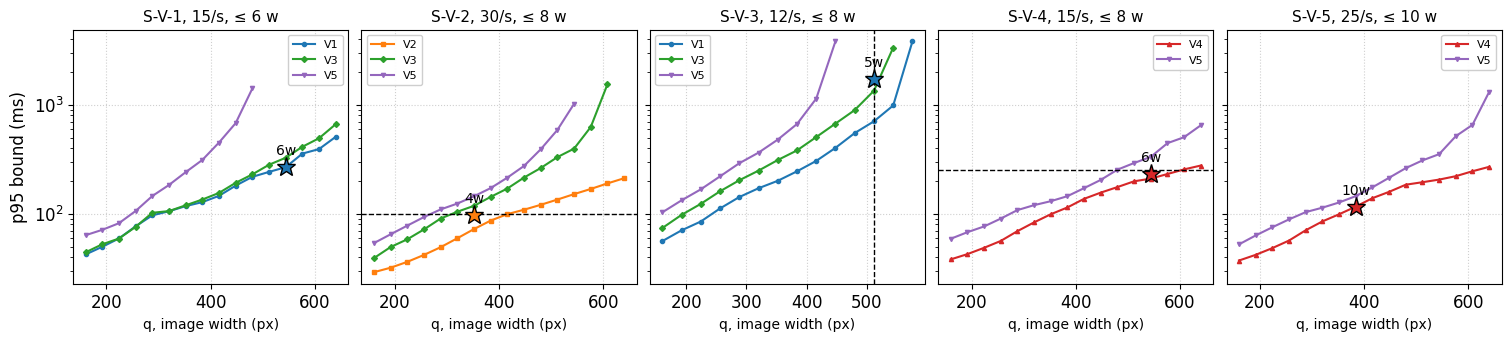

audio


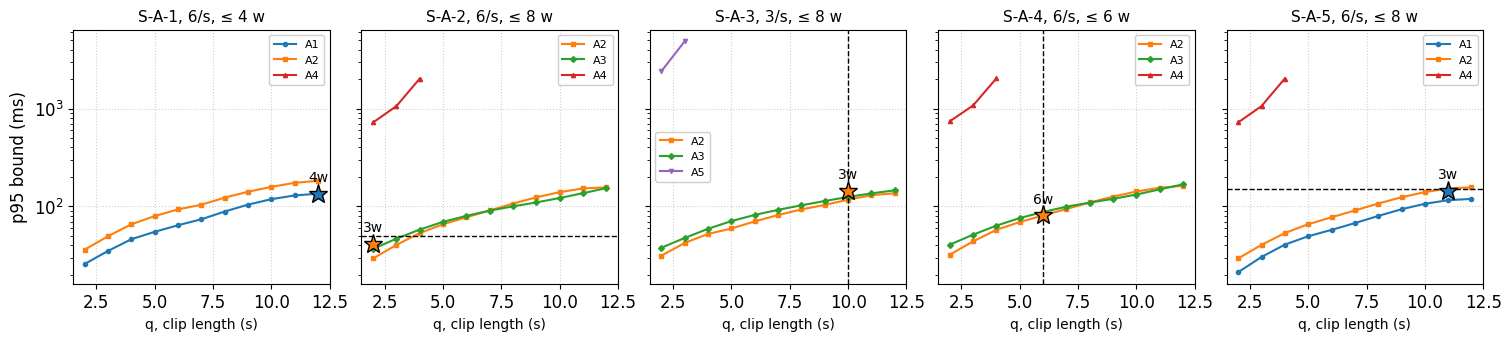

lidar


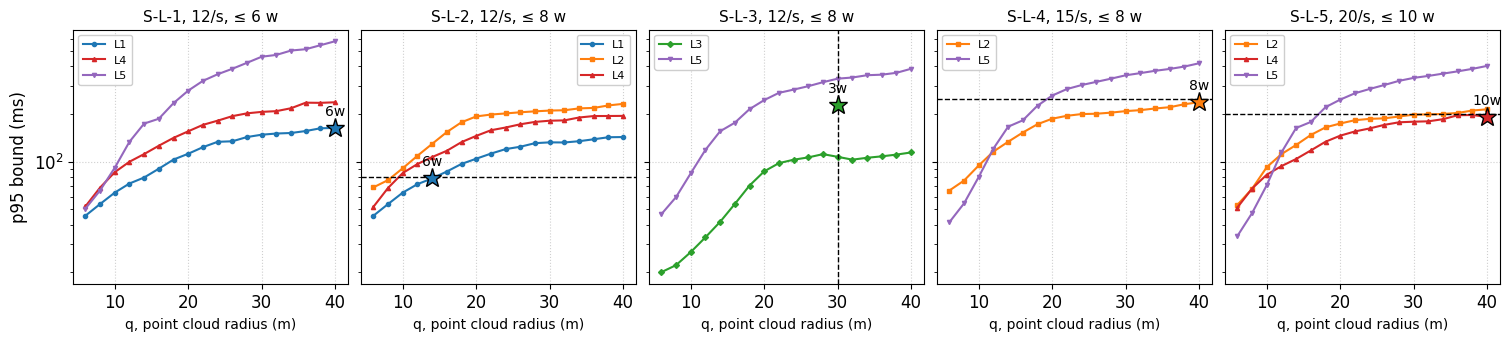

In [8]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.tradeoff_figure({s.name: compositions[s.name] for s in scenarios}, plans_slsqp, scenarios, app, WORKER_BUDGET, name=f"c2_slo_plans_{app}")

**Deployment table.** The SLSQP plan of every scenario in the knob names of the campaign (`shared.data_quality`,
`<node>.parallelism`, `<node>.cores` $= w_k + 0.5$, `<node>.model_size` in the column `knobs`), with the arrival rate
of the scenario to deploy it at and the predicted bound; written to `statics/slo_planning/c2_plans.csv`.

In [9]:
deployment = sp.deployment_table(plans_slsqp, {s.name: s.rate for scenarios in SCENARIOS.values() for s in scenarios})
sp.CACHE.mkdir(parents=True, exist_ok=True)
deployment.to_csv(sp.CACHE / "c2_plans.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(deployment.set_index(["application", "scenario"]))

arrival_rate  feasible composition  \
application scenario                                                        
vision      S-V-1 edge box                     15.0      True          V1   
            S-V-2 interactive AR               30.0      True          V2   
            S-V-3 forensic detail              12.0      True          V1   
            S-V-4 retail analytics             15.0      True          V4   
            S-V-5 traffic monitoring           25.0      True          V4   
audio       S-A-1 shared gateway                6.0      True          A1   
            S-A-2 voice assistant               6.0      True          A2   
            S-A-3 music archive                 3.0      True          A2   
            S-A-4 call analytics                6.0      True          A2   
            S-A-5 conferencing                  6.0      True          A1   
lidar       S-L-1 delivery robot               12.0      True          L1   
            S-L-2 collision avoidance          12.0      True          L1   
            S-L-3 HD mapping                   12.0      True          L3   
            S-L-4 fleet perception             15.0      True          L2   
            S-L-5 robotaxi                     20.0      True          L4   

                                         experiment  \
application scenario                                  
vision      S-V-1 edge box             b1u-vision-1   
            S-V-2 interactive AR       b1u-vision-2   
            S-V-3 forensic detail      b1u-vision-1   
            S-V-4 retail analytics     b1u-vision-4   
            S-V-5 traffic monitoring   b1u-vision-4   
audio       S-A-1 shared gateway        b1u-audio-1   
            S-A-2 voice assistant       b1u-audio-2   
            S-A-3 music archive         b1u-audio-2   
            S-A-4 call analytics        b1u-audio-2   
            S-A-5 conferencing          b1u-audio-1   
lidar       S-L-1 delivery robot        b1u-lidar-1   
            S-L-2 collision avoidance   b1u-lidar-1   
            S-L-3 HD mapping            b1u-lidar-3   
            S-L-4 fleet perception      b1u-lidar-2   
            S-L-5 robotaxi              b1u-lidar-4   

                                                                              services  \
application scenario                                                                     
vision      S-V-1 edge box                         detector → transformer → compressor   
            S-V-2 interactive AR                           faces → transformer → edges   
            S-V-3 forensic detail                  detector → transformer → compressor   
            S-V-4 retail analytics     transformer → denoiser → motion → codes → edges   
            S-V-5 traffic monitoring   transformer → denoiser → motion → codes → edges   
audio       S-A-1 shared gateway                        resampler → cleaner → features   
            S-A-2 voice assistant                            cleaner → voice → encoder   
            S-A-3 music archive                              cleaner → voice → encoder   
            S-A-4 call analytics                             cleaner → voice → encoder   
            S-A-5 conferencing                          resampler → cleaner → features   
lidar       S-L-1 delivery robot                      downsampler → ground → clusterer   
            S-L-2 collision avoidance                 downsampler → ground → clusterer   
            S-L-3 HD mapping                          downsampler → registrar → viewer   
            S-L-4 fleet perception                           ground → normals → packer   
            S-L-5 robotaxi                        ground → clusterer → viewer → packer   

                                       workers  predicted_p95_ms  \
application scenario                                               
vision      S-V-1 edge box                   6             267.4   
            S-V-2 interactive AR             4            